In [1]:
# Import the libraries required for data analysis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

# Convert the dataset into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target species
df["species"] = iris.target

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column data types
print("\nData types:")
print(df.dtypes)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display descriptive statistics
print("\nDescriptive statistics:")
display(df.describe())

Dataset shape: (150, 5)

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:
# Convert numeric labels into readable species names
df["species"] = df["species"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

# Check the updated dataset
display(df.head())

# Count flowers in each species
print(df["species"].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


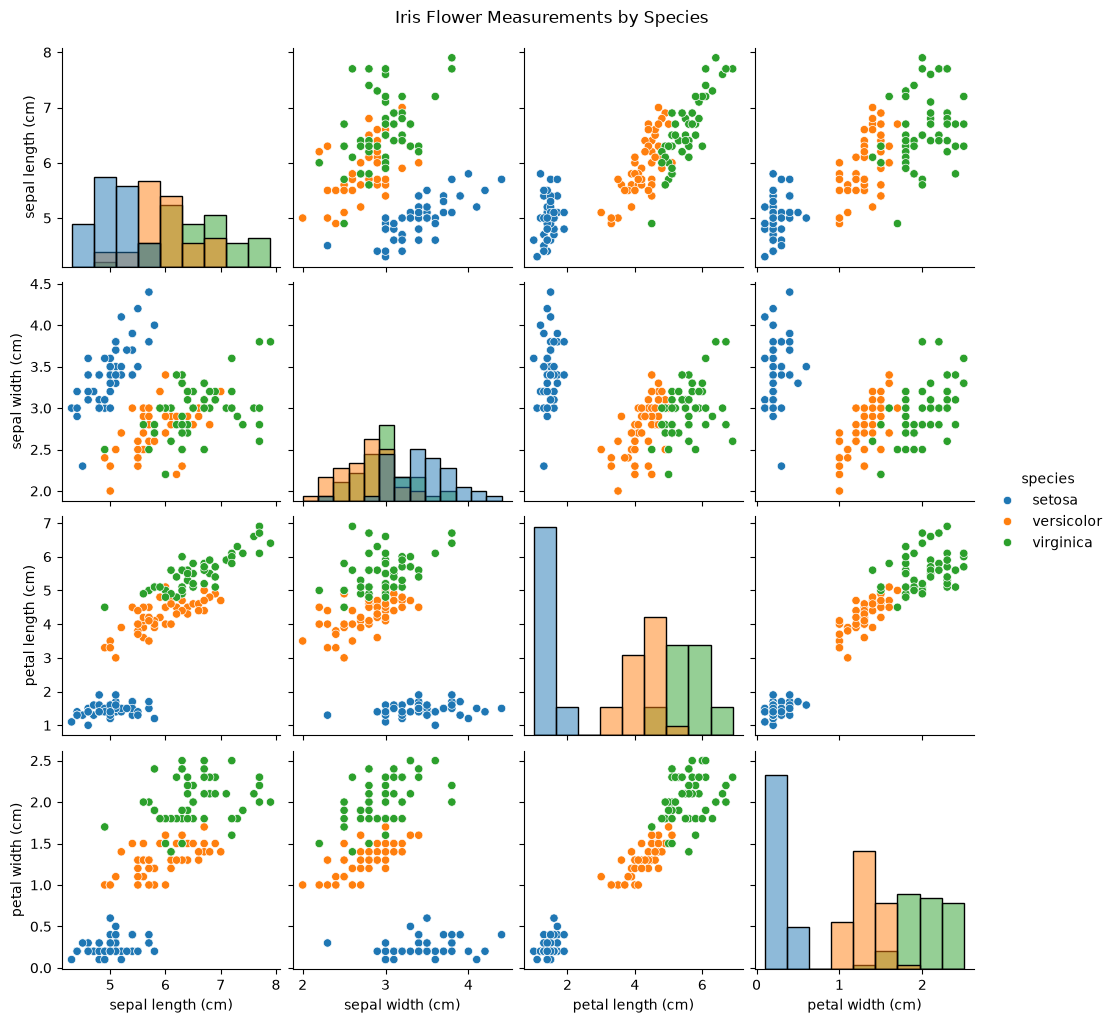

In [4]:
# Create a pairplot to compare flower measurements
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Iris Flower Measurements by Species",
    y=1.02
)

plt.show()

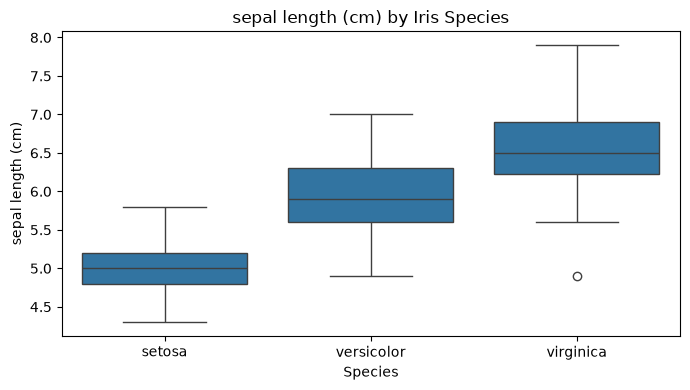

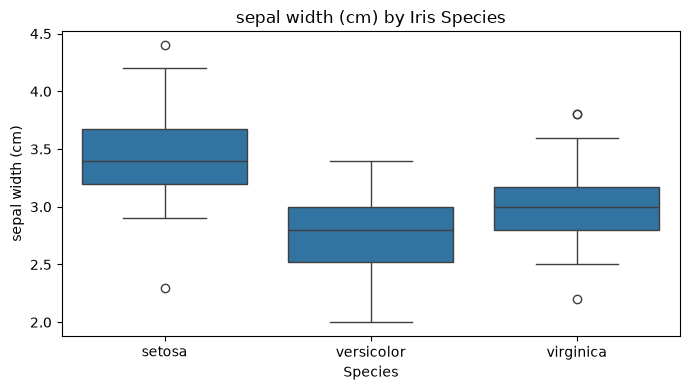

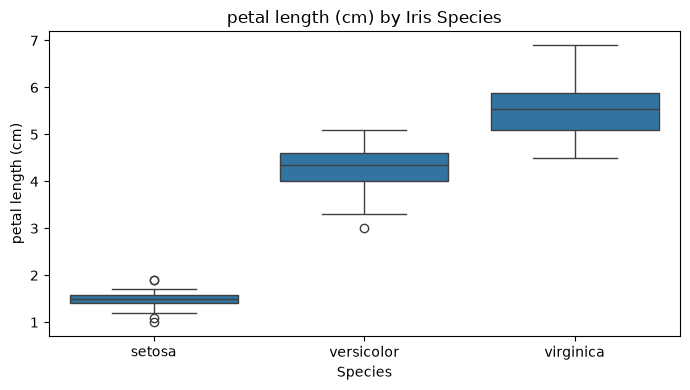

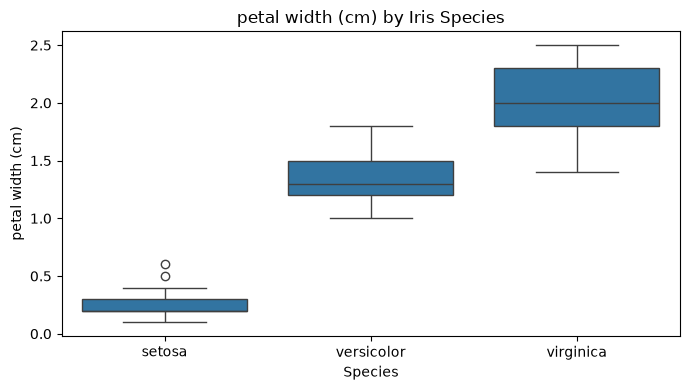

In [5]:
# Select the four numerical measurement columns
features = iris.feature_names

# Create one box plot for each feature
for feature in features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="species",
        y=feature
    )

    plt.title(f"{feature} by Iris Species")
    plt.xlabel("Species")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

In [6]:
# Import the function to split the dataset
from sklearn.model_selection import train_test_split

# Select the input features
X = df[iris.feature_names]

# Select the target variable
y = df["species"]

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining samples per species:")
print(y_train.value_counts())

print("\nTesting samples per species:")
print(y_test.value_counts())

Training data shape: (120, 4)
Testing data shape: (30, 4)

Training samples per species:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing samples per species:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [7]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
model_lr = LogisticRegression(max_iter=200)

# Train the model
model_lr.fit(X_train, y_train)

# Predict species for the test data
y_pred_lr = model_lr.predict(X_test)

print("Logistic Regression model trained successfully!")
print("\nFirst 10 actual labels:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted labels:")
print(y_pred_lr[:10])

Logistic Regression model trained successfully!

First 10 actual labels:
['setosa', 'virginica', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor']

First 10 predicted labels:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [8]:
# Import the KNN classifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create the KNN model
model_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
model_knn.fit(X_train, y_train)

# Predict species for the test data
y_pred_knn = model_knn.predict(X_test)

print("KNN model trained successfully!")

print("\nFirst 10 predicted labels:")
print(y_pred_knn[:10])

KNN model trained successfully!

First 10 predicted labels:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [9]:
# Import the accuracy metric
from sklearn.metrics import accuracy_score

# Calculate accuracy for both models
lr_accuracy = accuracy_score(y_test, y_pred_lr)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Display the comparison
print("Model Accuracy Comparison")
print("-" * 30)

print(f"Logistic Regression: {lr_accuracy:.2%}")
print(f"K-Nearest Neighbours: {knn_accuracy:.2%}")

Model Accuracy Comparison
------------------------------
Logistic Regression: 96.67%
K-Nearest Neighbours: 93.33%


In [10]:
# Import evaluation tools
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, y_pred_lr))

print("\nK-NEAREST NEIGHBOURS REPORT")
print(classification_report(y_test, y_pred_knn))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


K-NEAREST NEIGHBOURS REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



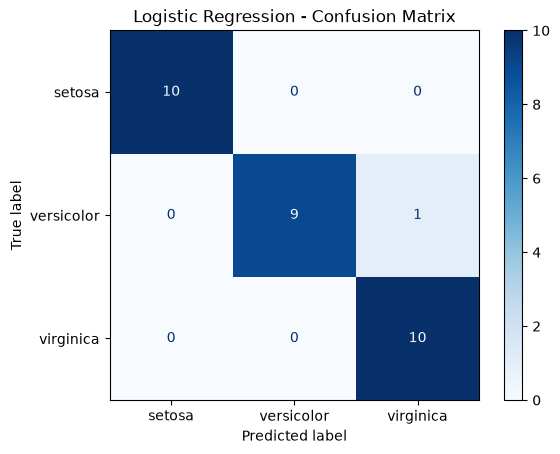

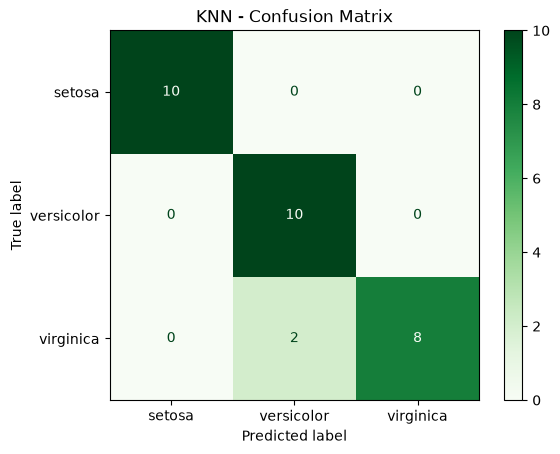

In [11]:
# Import the confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define the species order
species_names = ["setosa", "versicolor", "virginica"]

# Confusion matrix for Logistic Regression
cm_lr = confusion_matrix(
    y_test, y_pred_lr,
    labels=species_names
)

display_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=species_names
)

display_lr.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


# Confusion matrix for KNN
cm_knn = confusion_matrix(
    y_test, y_pred_knn,
    labels=species_names
)

display_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=species_names
)

display_knn.plot(cmap="Greens")
plt.title("KNN - Confusion Matrix")
plt.show()

In [12]:
# Compare models using accuracy
accuracies = {
    "Logistic Regression": lr_accuracy,
    "K-Nearest Neighbours": knn_accuracy
}

best_model_name = max(accuracies, key=accuracies.get)

print("Best-performing model:", best_model_name)
print(f"Test accuracy: {accuracies[best_model_name]:.2%}")

print("\nJustification:")
print(
    "Logistic Regression performed better than KNN "
    "on the held-out test set for this experiment."
)

Best-performing model: Logistic Regression
Test accuracy: 96.67%

Justification:
Logistic Regression performed better than KNN on the held-out test set for this experiment.


## Conclusion

The Iris Flower Classification project successfully applied machine learning to predict iris species from sepal and petal measurements.

Exploratory Data Analysis showed that petal length and petal width provide useful separation between species. Pairplots and box plots helped visualise the distributions and relationships among the four features.

Two classification algorithms were evaluated: Logistic Regression and K-Nearest Neighbours (KNN). Using an 80/20 stratified train-test split, Logistic Regression achieved **96.67% accuracy**, while KNN achieved **93.33% accuracy**.

Therefore, Logistic Regression was selected as the best-performing model for this experiment because it achieved higher accuracy on the held-out test set. The classification reports and confusion matrices provided additional insight into the models' precision, recall, F1-scores, and misclassifications.

The results are based on one train-test split, so they should not be interpreted as a guarantee of performance on every unseen dataset.

In [14]:
# Create a comparison table
results = pd.DataFrame({
    "Model": ["Logistic Regression", "K-Nearest Neighbours"],
    "Accuracy": [lr_accuracy, knn_accuracy]
})

# Display the comparison
display(results)

# Save results to a CSV file
import os

os.makedirs("outputs", exist_ok=True)
results.to_csv("outputs/model_comparison.csv", index=False)

print("Model comparison saved successfully.")

,Model,Accuracy
0,Logistic Regression,0.966667
1,K-Nearest Neighbours,0.933333


Model comparison saved successfully.
